# From return forecasts to portfolio decisions

This notebook runs the complete experiment on an artificial price sample. The purpose is to inspect the mechanics and compare allocation rules, not to claim an investment edge. See `docs/methodology.md` for the timing and cost conventions.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Image
from markowitz.data import load_prices, returns_from_prices
from markowitz.backtest import Config, run_backtest
from markowitz.portfolio import covariance, black_litterman, efficient_frontier

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
prices = load_prices(ROOT / "data/sample_prices.csv")
display(prices.head())
print(f"{len(prices):,} observations, {prices.shape[1]} artificial assets")

,Asset_01,Asset_02,Asset_03,Asset_04,Asset_05,Asset_06,Asset_07,Asset_08
date,,,,,,,,
2020-01-01,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
2020-01-02,100.115177,99.567983,100.017528,100.263001,99.648949,100.569664,99.043966,100.196455
2020-01-03,101.457696,100.373221,101.705499,100.817245,99.434794,100.889801,100.146556,101.045962
2020-01-06,100.005090,98.982150,101.071157,98.024270,98.889640,100.646635,99.157568,100.257202
2020-01-07,99.648970,97.870673,100.717260,97.370142,98.044271,101.729407,99.239996,100.530244


1,009 observations, 8 artificial assets


## 1. Inspect the input

Returns are calculated without forward-filling prices. All input series must be aligned before analysis. For real data, record the adjustment convention and avoid choosing today's surviving stocks retrospectively.

In [2]:
returns = returns_from_prices(prices)
display(pd.DataFrame({"annual_mean": returns.mean() * 252, "annual_volatility": returns.std() * np.sqrt(252)}))

,annual_mean,annual_volatility
Asset_01,-0.062152,0.144144
Asset_02,0.044377,0.110100
Asset_03,0.005641,0.122829
Asset_04,-0.182587,0.175648
Asset_05,-0.058052,0.129017
Asset_06,-0.085872,0.170571
Asset_07,-0.070250,0.130905
Asset_08,-0.051590,0.130945


## 2. Run a rolling experiment

A 252-observation training window is refitted every 21 observations. Signals are available one bar before execution. Ten basis points are charged on each unit of bought or sold notional, including initial investment.

In [3]:
config = Config(train_window=252, rebalance=21, cost_bps=10, max_weight=0.35)
result = run_backtest(prices, config)
display(result.metrics.round(4))

,total_return,cagr,volatility,sharpe,max_drawdown
Equal weight,-0.2593,-0.0953,0.1025,-1.1197,-0.3127
Minimum variance,-0.1171,-0.0407,0.0844,-0.6853,-0.2107
Forecast Markowitz,-0.2223,-0.0805,0.0975,-1.0147,-0.2953
Black-Litterman,-0.2152,-0.0777,0.0950,-1.0125,-0.2850


## 3. Audit a decision

Decision dates precede execution dates, which precede the first realized return. The equal-weight portfolio uses the full universe; the optimized portfolios honor the position cap. Weights below are rebalance targets, not daily rebalanced holdings.

In [4]:
display(result.forecasts.head(8))
display(result.weights.head(4))
display(result.trades.head(4))
weights = result.weights.filter(like="Asset_")
assert np.allclose(weights.sum(axis=1), 1)
assert (result.forecasts.decision_date < result.forecasts.execution_date).all()

,decision_date,execution_date,asset,predicted_daily_return,realized_daily_return,holding_days,selected
0,2020-12-18,2020-12-21,Asset_01,0.001419,0.001356,21,True
1,2020-12-18,2020-12-21,Asset_02,0.001032,0.000311,21,True
2,2020-12-18,2020-12-21,Asset_03,0.000433,0.000105,21,True
3,2020-12-18,2020-12-21,Asset_04,-0.000873,0.000065,21,True
4,2020-12-18,2020-12-21,Asset_05,0.000190,0.001976,21,True
5,2020-12-18,2020-12-21,Asset_06,0.000193,0.000591,21,True
6,2020-12-18,2020-12-21,Asset_07,0.000120,-0.000581,21,True
7,2020-12-18,2020-12-21,Asset_08,0.000653,0.000386,21,True


,execution_date,strategy,Asset_01,Asset_02,Asset_03,Asset_04,Asset_05,Asset_06,Asset_07,Asset_08
0,2020-12-21,Equal weight,0.125000,0.125,0.125000,1.250000e-01,1.250000e-01,1.250000e-01,1.250000e-01,0.125000
1,2020-12-21,Minimum variance,0.088569,0.350,0.155090,2.579534e-17,1.098608e-01,2.050623e-17,1.262461e-01,0.170235
2,2020-12-21,Forecast Markowitz,0.350000,0.350,0.059322,1.082952e-16,7.928859e-16,4.740274e-16,6.360513e-16,0.240678
3,2020-12-21,Black-Litterman,0.350000,0.350,0.083968,1.006471e-15,2.475180e-16,3.749963e-16,8.214221e-17,0.216032


,execution_date,strategy,gross_traded_fraction,cost_fraction,min_variance_fallback
0,2020-12-21,Equal weight,1.0,0.001,False
1,2020-12-21,Minimum variance,1.0,0.001,False
2,2020-12-21,Forecast Markowitz,1.0,0.001,False
3,2020-12-21,Black-Litterman,1.0,0.001,False


## 4. Inspect the Bayesian update

These are annual excess-return views relative to the risk-free assumption. The prior comes from an equal-weight reference allocation. The default view uncertainty is a heuristic, not a calibrated probability of success.

In [5]:
train = returns.iloc[:config.train_window]
cov = covariance(train)
reference = np.full(prices.shape[1], 1 / prices.shape[1])
views = train.mean().to_numpy() * 252 - config.risk_free
posterior, predictive = black_litterman(cov, reference, views)
display(pd.DataFrame({"prior_excess": 2.5 * cov @ reference, "view_excess": views, "posterior_excess": posterior}, index=prices.columns))
assert np.linalg.eigvalsh(predictive).min() > 0

,prior_excess,view_excess,posterior_excess
Asset_01,0.021679,0.089988,0.057835
Asset_02,0.014582,0.082207,0.048283
Asset_03,0.020987,0.045098,0.041359
Asset_04,0.032444,0.003493,0.042584
Asset_05,0.022308,0.059922,0.046388
Asset_06,0.029188,0.096419,0.064863
Asset_07,0.020537,-0.068790,-0.005084
Asset_08,0.020421,0.075380,0.052294


## 5. Read performance and forecast error separately

A forecast may reduce prediction error without improving the portfolio. Inspect the realized drawdown, concentration and cost burden as well as Sharpe. The chart below is the checked-in default run; use the CLI to regenerate it after changing the configuration.

Forecast RMSE: 0.002019
Zero-return forecast RMSE: 0.001959


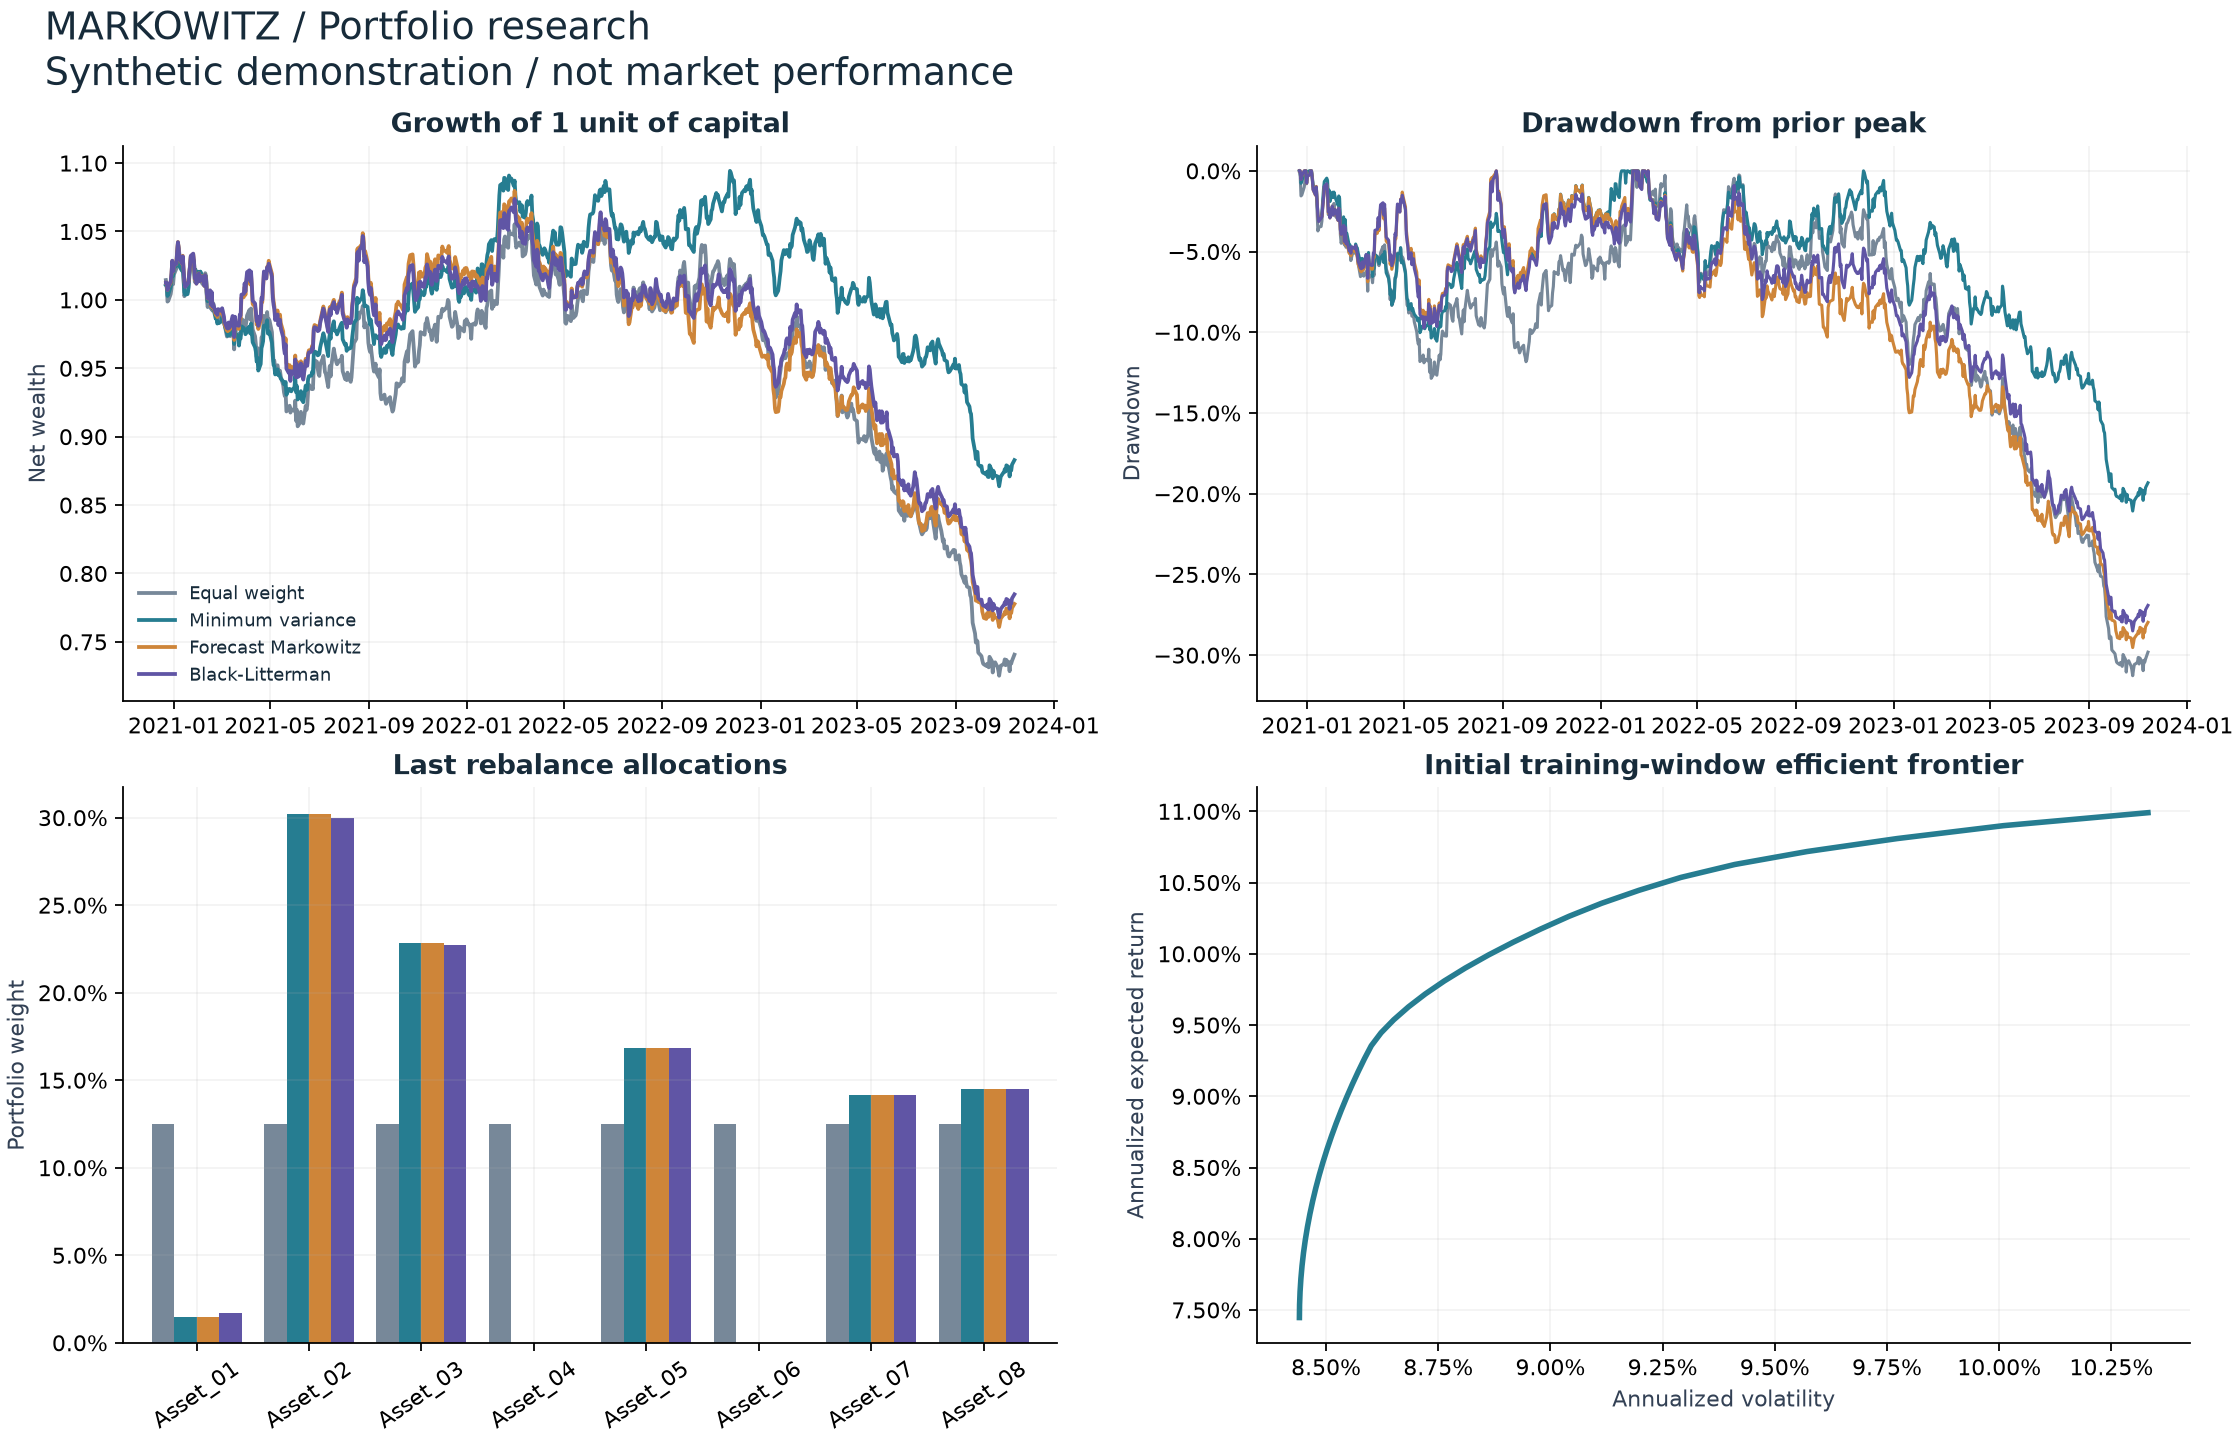

In [6]:
error = result.forecasts.predicted_daily_return - result.forecasts.realized_daily_return
print(f"Forecast RMSE: {np.sqrt(np.mean(error ** 2)):.6f}")
print(f"Zero-return forecast RMSE: {np.sqrt(np.mean(result.forecasts.realized_daily_return ** 2)):.6f}")
display(Image(filename=str(ROOT / "reports/demo/overview.png")))

## 6. Compare forecasting models

The table below contains actual runs of the provided sample. Run `python scripts/compare_models.py --neural --output reports/comparison` after installing the neural extra to reproduce it. Model selection should use a separate chronological validation design, not these test results.

In [7]:
comparison = pd.read_csv(ROOT / "reports/comparison/model_comparison.csv")
display(comparison[comparison.strategy == "Forecast Markowitz"].round(4))

,model,strategy,forecast_rmse,zero_forecast_rmse,total_return,cagr,volatility,sharpe,max_drawdown
2,historical,Forecast Markowitz,0.0019,0.002,-0.2211,-0.0800,0.0906,-1.0932,-0.2907
6,ridge,Forecast Markowitz,0.0020,0.002,-0.2223,-0.0805,0.0975,-1.0147,-0.2953
10,lstm,Forecast Markowitz,0.0020,0.002,-0.1352,-0.0473,0.0895,-0.7178,-0.2416
14,bilstm,Forecast Markowitz,0.0020,0.002,-0.2016,-0.0724,0.0949,-0.9526,-0.2927
18,cnn_bilstm,Forecast Markowitz,0.0020,0.002,-0.1655,-0.0586,0.0943,-0.8037,-0.2566


## What remains an empirical question

Synthetic data cannot establish usefulness in an actual market. The next study should use a point-in-time universe, multiple test periods, sensitivity to costs and training windows, and nested chronological tuning. A more complex network is only justified if it adds stable value over the historical-mean and ridge baselines.